# Toprak fotoğraflarıyla ilk Kaggle gönderimimiz

Önce iki numunenin fotoğrafını laboratuvar ölçümüyle eşleştireceğiz. Ardından eğitim numunelerinin ortalama eğrisini kullanarak ilk tahmin dosyamızı yazacağız. Fotoğraftan öğrenen modelleri daha sonra bu sonuçla karşılaştıracağız.

Kaggle'da yarışma verisini notebook'a ekleyip **Run All** düğmesine bas. Son hücre oluşturduğu dosyanın yolunu yazar.

## 1. Yarışma dosyalarını aç

Eğitim tablosundaki her satır bir fiziksel numuneyi temsil eder. Örnek gönderim tablosu ise tahmin yazacağımız numunelerin kimliklerini ve Kaggle'ın beklediği sütun adlarını verir.

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageOps

input_root = Path("/kaggle/input")
output_dir = Path("/kaggle/working")
label_paths = sorted(input_root.rglob("Training_labels_updated.csv"))
if not label_paths:
    label_paths = [p for p in input_root.rglob("train.csv") if "soil-grain-size" in str(p)]
if len(label_paths) != 1:
    raise ValueError("Yarışmanın veri klasörü bulunamadı veya birden fazla kopyası var. "
                     "Add Input bölümünde soil-grain-size-from-photos verisini kontrol et.")

data_dir = label_paths[0].parent

def read_table(path):
    return pd.read_csv(path, sep=None, engine="python", encoding="utf-8-sig", dtype=str).dropna(how="all")

labels = read_table(label_paths[0])
template = read_table(data_dir / "sample_submission.csv")
diameters = np.array([0.002, 0.0063, 0.02, 0.063, 0.2, 0.63, 2, 6.3, 20, 63, 200])

def columns_for(table):
    columns = {}
    for name in table.columns:
        try:
            diameter = float(name.strip().replace(",", "."))
        except ValueError:
            continue
        columns[diameter] = name
    return [columns[d] for d in diameters]

label_cols = columns_for(labels)
target_cols = columns_for(template)
def id_column(table):
    return next(name for name in table.columns if name.strip().lower() == "sample_id")

samples = labels[id_column(labels)].str.strip()
test_ids = template[id_column(template)]
curves = labels[label_cols].apply(lambda col: pd.to_numeric(col.str.replace(",", ".", regex=False))).to_numpy(float)
assert len(samples) >= 2 and samples.notna().all() and samples.is_unique
assert len(test_ids) > 0 and test_ids.notna().all() and test_ids.is_unique
assert np.isfinite(curves).all()
print(f"{len(samples)} eğitim numunesi ve {len(test_ids)} tahmin edilecek numune bulundu.")

24 eğitim numunesi ve 10 tahmin edilecek numune bulundu.


## 2. İki numuneyi karşılaştır

İki milimetrelik elekten geçen kütle oranı en düşük ve en yüksek olan eğitim numunelerini seçiyoruz. Soldaki fotoğrafta gördüğün dokuyu sağdaki eğriyle karşılaştır. Turuncu nokta, ağırlıkça yüzde kaçının 2 mm'den ince olduğunu gösterir.

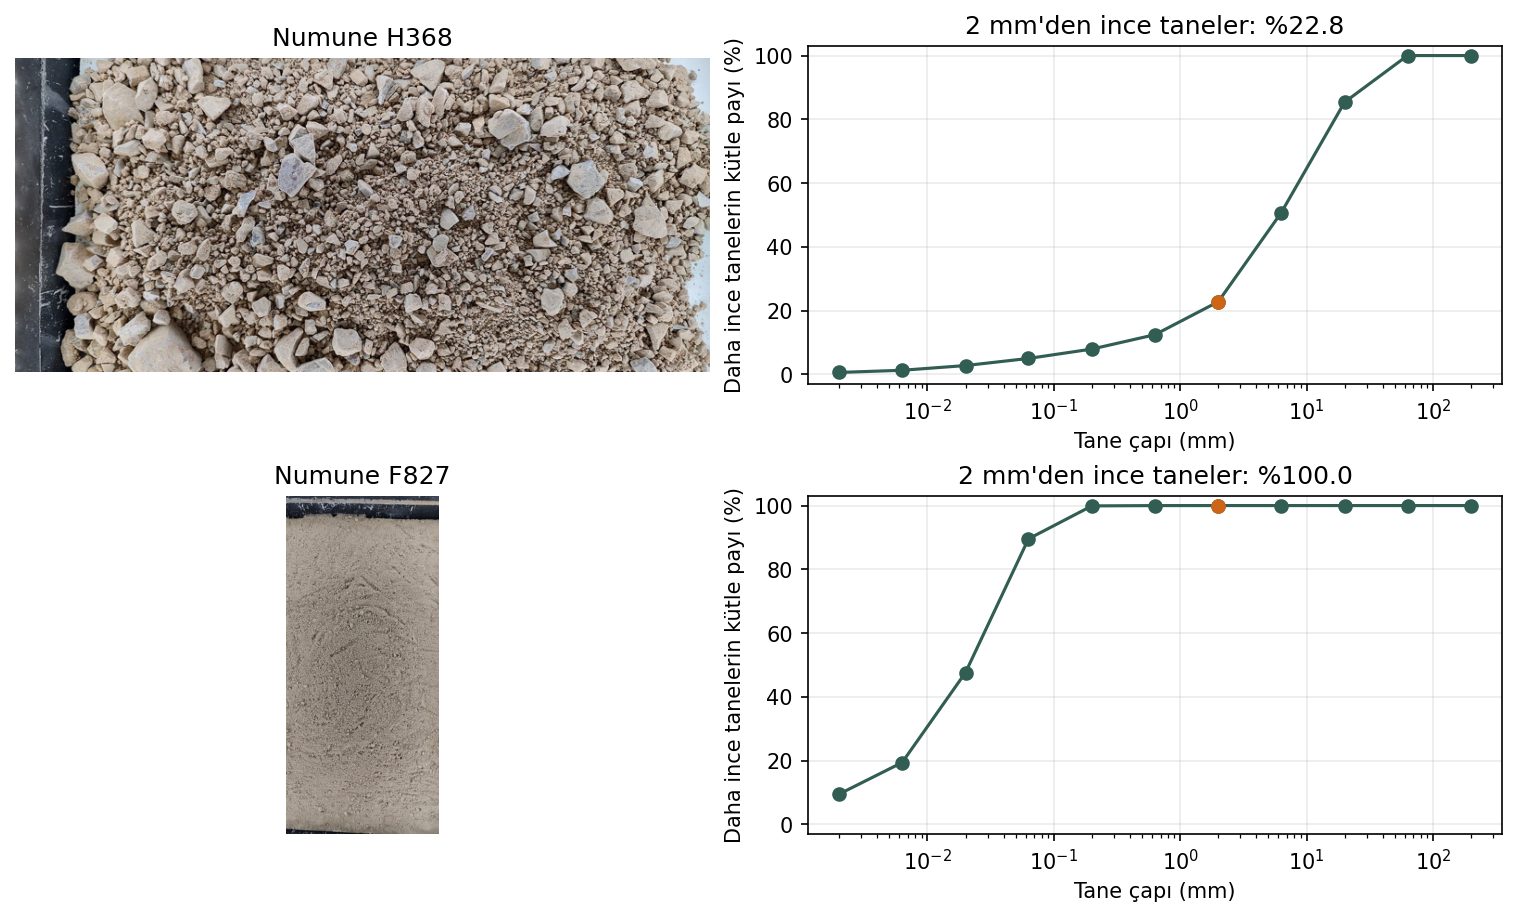

In [2]:
photos = sorted(p for p in data_dir.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
two_mm = list(diameters).index(2)
order = np.argsort(curves[:, two_mm], kind="stable")
fig, axes = plt.subplots(2, 2, figsize=(10, 6), constrained_layout=True)
for row, index in enumerate([order[0], order[-1]]):
    sample = samples.iloc[index]
    pattern = re.compile(r"(?<![a-z0-9])" + re.escape(sample) + r"(?![a-z0-9])", re.I)
    photo = next((p for p in photos if pattern.search(p.stem)), None)
    left, right = axes[row]
    if photo is not None:
        with Image.open(photo) as original:
            preview = ImageOps.exif_transpose(original).convert("RGB")
            preview.thumbnail((750, 500))
            left.imshow(preview)
    else:
        left.text(0.5, 0.5, "Eşleşen fotoğraf bulunamadı", ha="center", va="center")
    left.set_title(f"Numune {sample}")
    left.set_axis_off()
    right.semilogx(diameters, curves[index], "o-", color="#315d53")
    right.scatter(2, curves[index, two_mm], color="#cd6517", zorder=3)
    right.set(xlabel="Tane çapı (mm)", ylabel="Daha ince tanelerin kütle payı (%)",
              ylim=(-3, 103), title=f"2 mm'den ince taneler: %{curves[index, two_mm]:.1f}")
    right.grid(alpha=0.25)
plt.show()

## 3. Ortalama eğriyi yeni numunelerde sına

Her turda bir numuneyi ayırıyor, diğerlerinin ortalamasıyla onun eğrisini tahmin ediyoruz. Aşağıdaki sayı yerel kontrol puanımızdır. Yarışmanın logaritmik ağırlıklı EMD ölçüsünde daha düşük sonuç daha iyidir.

In [3]:
log_widths = np.diff(np.log10(diameters))
errors = []
for i, measured in enumerate(curves):
    predicted = np.delete(curves, i, axis=0).mean(axis=0)
    errors.append(np.abs(measured[:-1] - predicted[:-1]) @ log_widths)
print(f"Ortalama eğrinin yerel EMD puanı: {np.mean(errors):.2f}")

Ortalama eğrinin yerel EMD puanı: 89.89


## 4. İlk gönderimi oluştur

Artık tüm eğitim numunelerini kullanıyoruz. Her test numunesine aynı ortalama eğriyi yazıyoruz. Dosyayı yarışma sayfasındaki **Submit Predictions** seçeneğiyle yükleyebilirsin.

In [4]:
mean_curve = curves.mean(axis=0)
assert np.all((mean_curve >= 0) & (mean_curve <= 100))
assert np.all(np.diff(mean_curve) >= 0) and np.isclose(mean_curve[-1], 100)
mean_curve[-1] = 100.0
submission = template.copy()
for name, value in zip(target_cols, mean_curve):
    submission[name] = value

output_dir.mkdir(exist_ok=True, parents=True)
path = output_dir / "submission.csv"
submission.to_csv(path, index=False, float_format="%.8f")
saved = pd.read_csv(path, dtype={id_column(template): str})
assert saved.columns.tolist() == template.columns.tolist()
assert saved[id_column(template)].tolist() == test_ids.tolist()
assert np.allclose(saved[target_cols].to_numpy(), mean_curve, rtol=0, atol=1e-8)
print(f"İlk gönderim hazır: {path}")
print(f"{len(saved)} numune için tahmin yazıldı.")
saved.head(3)

İlk gönderim hazır: outputs\submission.csv
10 numune için tahmin yazıldı.
